# ICD 341 — Labs 9–13
**NAME: MAINZA MUYA**     
**STUDENT NUMBRE :202406802**

Contents: Lab 1 Bootstrap & resampling · Lab 2 Bayesian MCMC · Lab 3 Advanced simulation · Lab 4 Testing, estimators, packaging · Lab 5 Performance and scalability

Optional libraries used: `numba`, `dask[array]`, `pymc`, `scikit-learn`, `joblib`. Install with
`pip install numpy scipy matplotlib scikit-learn joblib numba "dask[array]" pymc pytest`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import time

SEED = 341

---
# Lab 1: Bootstrap & resampling
## Q1. Bootstrap the mean of [3, 4, 5, 7, 8, 9] and report a 95% percentile interval
Resample the data **with replacement** (same size n = 6), compute the mean of each resample, and take the 2.5th and 97.5th percentiles of the bootstrap distribution.

Sample mean              : 6.0000
Bootstrap mean of means  : 5.9933
Bootstrap SE             : 0.8767
95% percentile interval  : (4.333, 7.667)


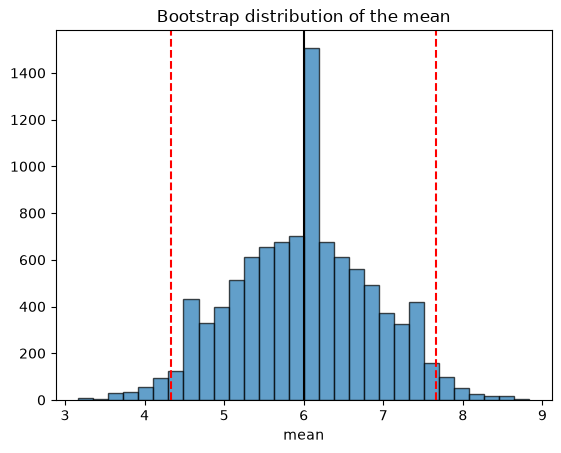

In [2]:
data = np.array([3, 4, 5, 7, 8, 9])
n = len(data)
B = 10_000
rng = np.random.default_rng(SEED)

idx = rng.integers(0, n, size=(B, n))          # B resamples of indices
boot_means = data[idx].mean(axis=1)

lo, hi = np.percentile(boot_means, [2.5, 97.5])
print(f"Sample mean              : {data.mean():.4f}")
print(f"Bootstrap mean of means  : {boot_means.mean():.4f}")
print(f"Bootstrap SE             : {boot_means.std(ddof=1):.4f}")
print(f"95% percentile interval  : ({lo:.3f}, {hi:.3f})")

plt.hist(boot_means, bins=30, edgecolor="k", alpha=.7)
plt.axvline(lo, color="r", ls="--"); plt.axvline(hi, color="r", ls="--")
plt.axvline(data.mean(), color="k"); plt.title("Bootstrap distribution of the mean")
plt.xlabel("mean"); plt.show()

**Interpretation.** The sample mean is 6. The 95% percentile interval (roughly 4.3 to 7.7) is a range of plausible values for the population mean, obtained without assuming a distribution. With only n = 6 observations the interval is wide and the bootstrap distribution is discrete/lumpy.

## Q2. Bootstrap the median of the same data

Sample median             : 6.0
Bootstrap SE of median    : 1.3782
95% percentile interval   : (3.500, 8.500)


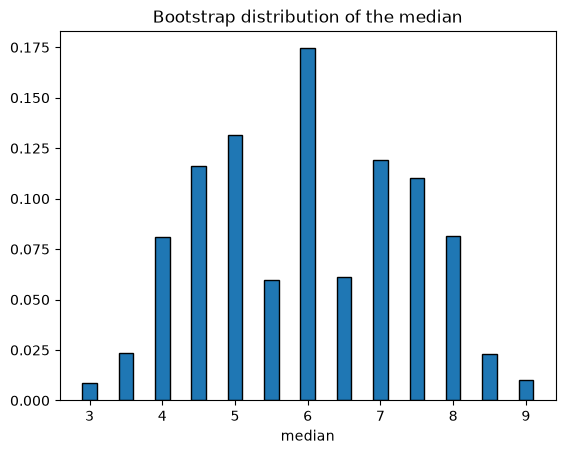

In [3]:
boot_medians = np.median(data[idx], axis=1)    # reuse same resamples
lo_m, hi_m = np.percentile(boot_medians, [2.5, 97.5])
print(f"Sample median             : {np.median(data)}")
print(f"Bootstrap SE of median    : {boot_medians.std(ddof=1):.4f}")
print(f"95% percentile interval   : ({lo_m:.3f}, {hi_m:.3f})")

vals, counts = np.unique(boot_medians, return_counts=True)
plt.bar(vals, counts / B, width=.2, edgecolor="k")
plt.title("Bootstrap distribution of the median"); plt.xlabel("median"); plt.show()

**Note.** The median of 6 points can only take a few values (averages of two order statistics), so the bootstrap distribution is very discrete. The bootstrap is less reliable for the median with tiny samples than for the mean.

## Q3. Parametric bootstrap from a fitted normal model
Fit $N(\hat\mu,\hat\sigma^2)$ by maximum likelihood, then simulate new datasets **from the fitted model** (instead of resampling the data), and recompute the statistic.

Fitted normal: mu = 6.000, sigma = 2.160
Parametric bootstrap mean  : SE = 0.876, 95% PI = (4.290, 7.702)
Parametric bootstrap median: SE = 1.000, 95% PI = (4.036, 7.977)


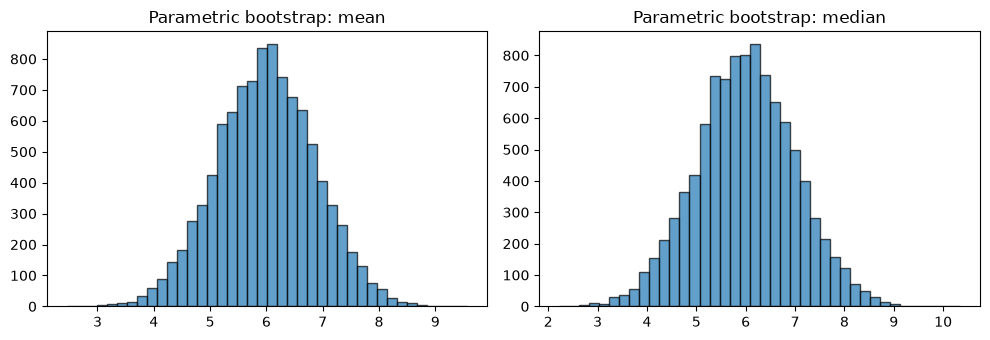

In [4]:
mu_hat = data.mean()
sigma_hat = data.std(ddof=0)                   # MLE of sigma
print(f"Fitted normal: mu = {mu_hat:.3f}, sigma = {sigma_hat:.3f}")

rng = np.random.default_rng(SEED)
sims = rng.normal(mu_hat, sigma_hat, size=(B, n))   # B synthetic datasets of size n
pb_means   = sims.mean(axis=1)
pb_medians = np.median(sims, axis=1)

for name, arr in [("mean", pb_means), ("median", pb_medians)]:
    l, h = np.percentile(arr, [2.5, 97.5])
    print(f"Parametric bootstrap {name:6s}: SE = {arr.std(ddof=1):.3f}, 95% PI = ({l:.3f}, {h:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(pb_means, bins=40, edgecolor="k", alpha=.7);   ax[0].set_title("Parametric bootstrap: mean")
ax[1].hist(pb_medians, bins=40, edgecolor="k", alpha=.7); ax[1].set_title("Parametric bootstrap: median")
plt.tight_layout(); plt.show()

The parametric bootstrap gives a smooth distribution (no discreteness) but is only as good as the normal assumption.

## Q4. One way data leakage can occur during model validation
**Pre-processing fitted on all the data before the train/test split.** For example, if we standardise features (or impute, select features, or do PCA) using the mean and standard deviation of the *entire* dataset and then split, information about the test set has leaked into the training pipeline. The validation score becomes optimistically biased because the model has indirectly "seen" the test data.

Other common forms: duplicates or near-duplicates in both train and test, using future information in time-series, and tuning hyperparameters on the test set.

**Fix:** split first, fit every pre-processing step on the training fold only, and wrap everything in a `Pipeline` so it is refit inside each cross-validation fold. Demonstration with feature selection on pure noise:

In [5]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
X = rng.normal(size=(60, 2000))       # pure noise features
y = rng.integers(0, 2, size=60)       # random labels -> true accuracy is 50%

# WRONG: select features using ALL data, then cross-validate (leakage)
X_sel = SelectKBest(f_classif, k=20).fit_transform(X, y)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y, cv=5).mean()

# RIGHT: selection happens inside each training fold
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe, X, y, cv=5).mean()

print(f"Leaky CV accuracy  : {leaky:.2f}   (looks great, but is meaningless)")
print(f"Honest CV accuracy : {honest:.2f}   (about chance, as it should be)")

Leaky CV accuracy  : 0.95   (looks great, but is meaningless)
Honest CV accuracy : 0.50   (about chance, as it should be)


---
# Lab 2: Bayesian MCMC
## Q1. Random-walk Metropolis–Hastings for a standard normal target
Target $\pi(x)\propto e^{-x^2/2}$. Proposal $x^*=x+\epsilon,\ \epsilon\sim N(0,s^2)$. Accept with probability $\min\{1, \pi(x^*)/\pi(x)\}$ (symmetric proposal).

Acceptance rate: 0.44
Mean = 0.017 (true 0),  SD = 1.000 (true 1)


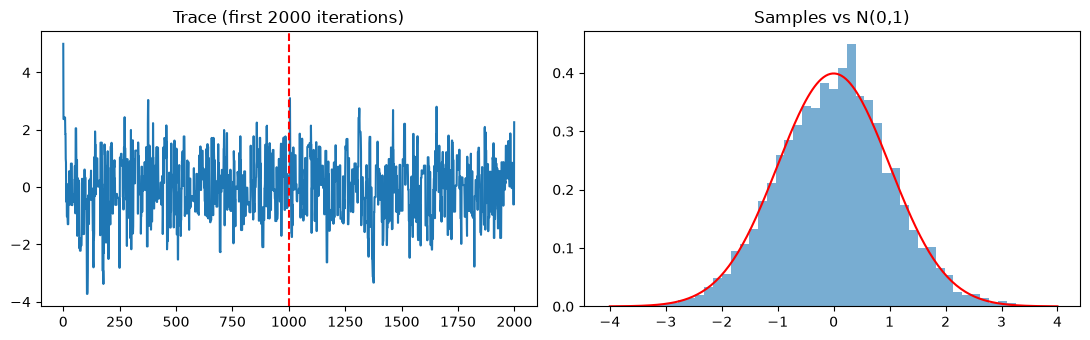

In [6]:
def rw_metropolis(log_target, x0, n_iter, step, rng):
    x = x0
    lp = log_target(x)
    chain = np.empty(n_iter)
    accepted = 0
    for i in range(n_iter):
        prop = x + step * rng.normal()
        lp_prop = log_target(prop)
        if np.log(rng.uniform()) < lp_prop - lp:      # accept/reject on log scale
            x, lp = prop, lp_prop
            accepted += 1
        chain[i] = x
    return chain, accepted / n_iter

log_std_normal = lambda x: -0.5 * x**2

rng = np.random.default_rng(SEED)
chain, acc = rw_metropolis(log_std_normal, x0=5.0, n_iter=20_000, step=2.4, rng=rng)
burn = 1000
post = chain[burn:]
print(f"Acceptance rate: {acc:.2f}")
print(f"Mean = {post.mean():.3f} (true 0),  SD = {post.std():.3f} (true 1)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(chain[:2000]); ax[0].axvline(burn, color="r", ls="--"); ax[0].set_title("Trace (first 2000 iterations)")
xs = np.linspace(-4, 4, 200)
ax[1].hist(post, bins=50, density=True, alpha=.6); ax[1].plot(xs, stats.norm.pdf(xs), "r"); ax[1].set_title("Samples vs N(0,1)")
plt.tight_layout(); plt.show()

The chain starts far away at 5 and quickly moves to the target (burn-in). A step size of about 2.4 gives an acceptance rate near the 0.44 optimum for 1-D.

## Q2. Bernoulli probability with a Beta(2,2) prior; 8 successes in 12 trials
Conjugacy gives the exact posterior $\text{Beta}(2+8,\,2+4)=\text{Beta}(10,6)$, with mean $10/16=0.625$. We estimate it by MCMC and compare with the exact answer.

Acceptance rate : 0.56
MCMC  posterior mean = 0.6228,  95% CI = [0.38  0.831]
Exact posterior mean = 0.6250,  95% CI = 0.384, 0.837
MLE (k/N) = 0.667  -> prior pulls the estimate toward 0.5


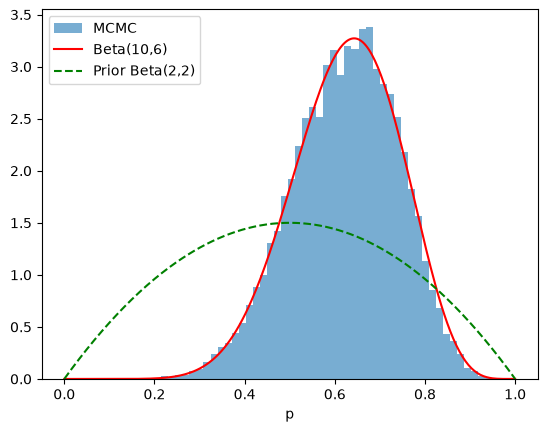

In [7]:
k, N = 8, 12
a0, b0 = 2, 2

def log_post(p):
    if p <= 0 or p >= 1:
        return -np.inf
    return stats.beta.logpdf(p, a0, b0) + k*np.log(p) + (N-k)*np.log(1-p)

rng = np.random.default_rng(SEED)
chain_p, acc = rw_metropolis(log_post, x0=0.5, n_iter=30_000, step=0.2, rng=rng)
post_p = chain_p[2000:]

exact = stats.beta(a0 + k, b0 + N - k)
print(f"Acceptance rate : {acc:.2f}")
print(f"MCMC  posterior mean = {post_p.mean():.4f},  95% CI = {np.percentile(post_p,[2.5,97.5]).round(3)}")
print(f"Exact posterior mean = {exact.mean():.4f},  95% CI = {exact.interval(0.95)[0]:.3f}, {exact.interval(0.95)[1]:.3f}")
print(f"MLE (k/N) = {k/N:.3f}  -> prior pulls the estimate toward 0.5")

ps = np.linspace(0, 1, 300)
plt.hist(post_p, bins=50, density=True, alpha=.6, label="MCMC")
plt.plot(ps, exact.pdf(ps), "r", label="Beta(10,6)")
plt.plot(ps, stats.beta.pdf(ps, a0, b0), "g--", label="Prior Beta(2,2)")
plt.legend(); plt.xlabel("p"); plt.show()

## Q3. Trace plots, ACF, R-hat and ESS
| Diagnostic | What it is | What you want to see |
|---|---|---|
| **Trace plot** | Sampled value against iteration, for each chain. | A "fuzzy caterpillar": stationary, no trends or long flat stretches, and multiple chains overlapping and mixing. Drift or stickiness means poor convergence or mixing. |
| **ACF** (autocorrelation function) | Correlation between draws $\ell$ iterations apart, plotted against lag $\ell$. | Decays quickly to ~0. Slow decay means highly dependent draws, so each sample carries little new information. |
| **R-hat** ($\hat R$, Gelman–Rubin) | Compares between-chain variance with within-chain variance across several chains started from dispersed points. | Close to 1 (commonly < 1.01; < 1.05 older rule). Large values mean chains have not converged to the same distribution. |
| **ESS** (effective sample size) | Number of *independent* draws that would give the same Monte-Carlo precision: $\text{ESS}\approx n/(1+2\sum_{\ell}\rho_\ell)$. | As large as possible (rule of thumb > 400 total, > 100 per chain). ESS much smaller than n signals strong autocorrelation. Monte-Carlo SE $\approx \sigma/\sqrt{\text{ESS}}$. |

Below: a from-scratch implementation applied to 4 chains from the Q2 posterior.

R-hat = 1.0005
ESS per chain : [1003, 912, 910, 1050] (of 4500 draws each)


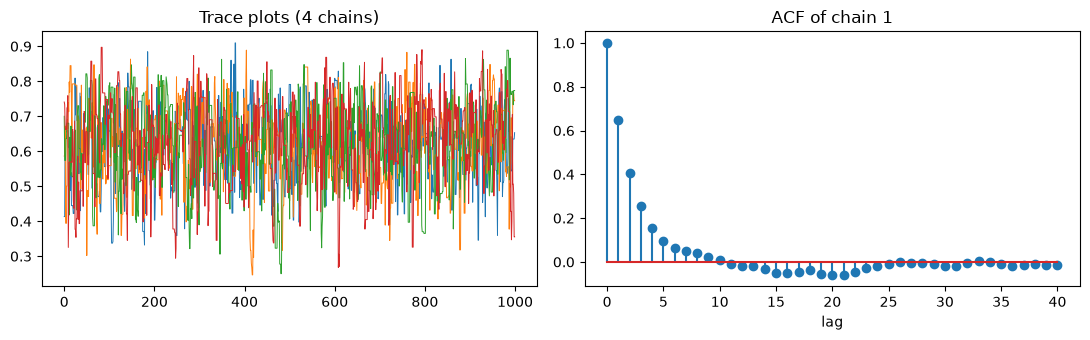

In [8]:
def acf(x, max_lag=50):
    x = np.asarray(x) - np.mean(x)
    f = np.fft.rfft(x, n=2*len(x))
    ac = np.fft.irfft(f * np.conj(f))[:len(x)]
    return (ac / ac[0])[:max_lag+1]

def ess(x):
    """Effective sample size for one chain (initial positive sequence)."""
    rho = acf(x, max_lag=len(x)//2)
    s = 0.0
    for t in range(1, len(rho) - 1, 2):
        pair = rho[t] + rho[t+1]
        if pair < 0:
            break
        s += pair
    return len(x) / (1 + 2*s)

def rhat(chains):
    """Gelman-Rubin R-hat; chains has shape (m, n)."""
    chains = np.asarray(chains)
    m, n = chains.shape
    W = chains.var(axis=1, ddof=1).mean()
    B_ = n * chains.mean(axis=1).var(ddof=1)
    var_hat = (n-1)/n * W + B_/n
    return np.sqrt(var_hat / W)

# 4 chains, dispersed starting points
rng = np.random.default_rng(SEED)
chains = np.array([rw_metropolis(log_post, x0, 5000, 0.2, rng)[0] for x0 in (0.1, 0.4, 0.7, 0.95)])
chains_bi = chains[:, 500:]

print(f"R-hat = {rhat(chains_bi):.4f}")
print("ESS per chain :", [round(ess(c)) for c in chains_bi], f"(of {chains_bi.shape[1]} draws each)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for c in chains: ax[0].plot(c[:1000], lw=.7)
ax[0].set_title("Trace plots (4 chains)")
ax[1].stem(acf(chains_bi[0], 40)); ax[1].set_title("ACF of chain 1"); ax[1].set_xlabel("lag")
plt.tight_layout(); plt.show()

## Q4. PyMC model for normally distributed observations
Model: $y_i\sim N(\mu,\sigma^2)$ with weakly informative priors $\mu\sim N(0,10^2)$, $\sigma\sim\text{HalfNormal}(5)$.

g++ not available, if using conda: `conda install gxx`
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [mu, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


        mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu     4.895  0.223      4.5      5.2     4135     2655  1.00    0.0035  0.0034
sigma  2.187  0.157        2      2.5     3989     2364  1.00    0.0025  0.0027


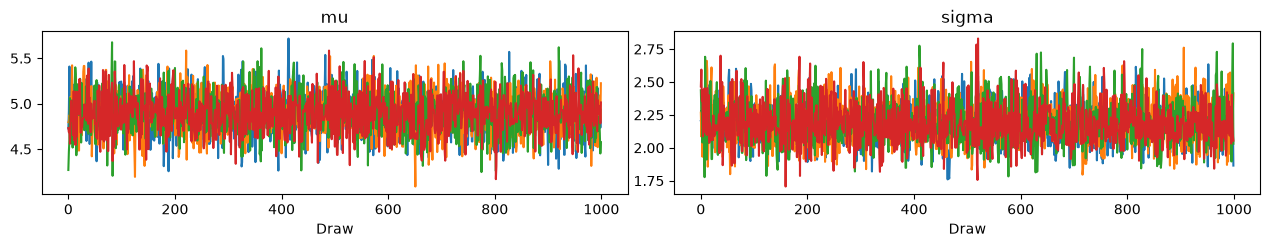

In [9]:
try:
    import pymc as pm
    import arviz as az

    rng = np.random.default_rng(SEED)
    y_obs = rng.normal(loc=5.0, scale=2.0, size=100)    # simulated data: true mu=5, sigma=2

    with pm.Model() as normal_model:
        mu    = pm.Normal("mu", mu=0, sigma=10)
        sigma = pm.HalfNormal("sigma", sigma=5)
        y     = pm.Normal("y", mu=mu, sigma=sigma, observed=y_obs)

        idata = pm.sample(1000, tune=1000, chains=4, random_seed=SEED, progressbar=False)

    print(az.summary(idata, var_names=["mu", "sigma"]))   # includes ess_bulk and r_hat
    az.plot_trace(idata, var_names=["mu", "sigma"]); plt.tight_layout(); plt.show()
except ImportError:
    print("PyMC / ArviZ not installed here. Install with:  pip install pymc arviz  and re-run this cell.")

`az.summary` reports posterior mean, HDI, `ess_bulk`, `ess_tail` and `r_hat`, i.e. the diagnostics from Q3. The posterior for $\mu$ and $\sigma$ should concentrate near 5 and 2.

---
# Lab 3: Advanced simulation
## Q1. 5,000 exponential samples via inverse transform (rate λ = 3)
CDF: $F(x)=1-e^{-\lambda x}$. Inverse: $F^{-1}(u)=-\ln(1-u)/\lambda$. If $U\sim U(0,1)$ then $X=F^{-1}(U)\sim\text{Exp}(\lambda)$.

Sample mean = 0.3333  (theory 1/lam = 0.3333)
Sample var  = 0.1099  (theory 1/lam^2 = 0.1111)
KS test vs Exp(3): KstestResult(statistic=np.float64(0.008788540403120354), pvalue=np.float64(0.8313175723661224), statistic_location=np.float64(0.05229144981792445), statistic_sign=np.int8(-1))


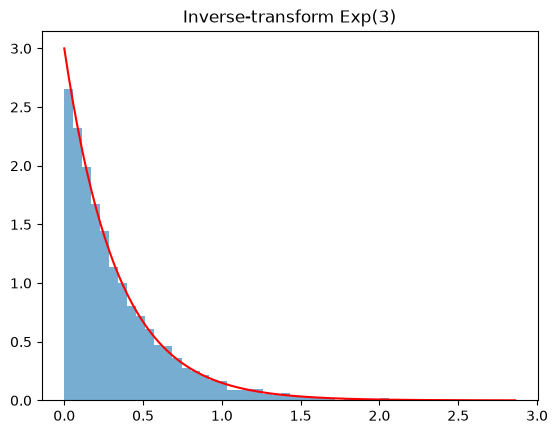

In [10]:
rng = np.random.default_rng(SEED)
lam = 3.0
u = rng.uniform(size=5000)
x_exp = -np.log(1 - u) / lam

print(f"Sample mean = {x_exp.mean():.4f}  (theory 1/lam = {1/lam:.4f})")
print(f"Sample var  = {x_exp.var(ddof=1):.4f}  (theory 1/lam^2 = {1/lam**2:.4f})")
print("KS test vs Exp(3):", stats.kstest(x_exp, "expon", args=(0, 1/lam)))

xs = np.linspace(0, x_exp.max(), 200)
plt.hist(x_exp, bins=50, density=True, alpha=.6)
plt.plot(xs, lam*np.exp(-lam*xs), "r"); plt.title("Inverse-transform Exp(3)"); plt.show()

## Q2. Sample from a categorical distribution with probabilities [0.1, 0.6, 0.3]
Build the cumulative probabilities `[0.1, 0.7, 1.0]`, draw uniforms, and find which interval each falls in.

In [11]:
probs = np.array([0.1, 0.6, 0.3])
cum = np.cumsum(probs)
rng = np.random.default_rng(SEED)
u = rng.uniform(size=10_000)
cat = np.searchsorted(cum, u, side="right")      # category index 0,1,2

emp = np.bincount(cat, minlength=3) / len(cat)
print("Target   :", probs)
print("Empirical:", emp.round(4))

# Built-in check
alt = rng.choice(3, size=10_000, p=probs)
print("rng.choice:", (np.bincount(alt, minlength=3)/len(alt)).round(4))

Target   : [0.1 0.6 0.3]
Empirical: [0.1025 0.6022 0.2953]
rng.choice: [0.0977 0.593  0.3093]


## Q3. Rejection sampling for Beta(2,2)
Target density $f(x)=6x(1-x)$ on [0,1], maximum $f(0.5)=1.5$. Use proposal $g=U(0,1)$ and constant $M=1.5$, so that $f(x)\le M g(x)$. Draw $x\sim g$, $u\sim U(0,1)$; accept if $u\le f(x)/(M g(x))=4x(1-x)$. The expected acceptance rate is $1/M\approx 0.667$.

Acceptance rate = 0.662  (theory 0.667)
Mean = 0.5016 (theory 0.5),  Var = 0.0499 (theory 0.0500)
KS test vs Beta(2,2): KstestResult(statistic=np.float64(0.00979401230100424), pvalue=np.float64(0.2908517077696461), statistic_location=np.float64(0.3820762072313927), statistic_sign=np.int8(-1))


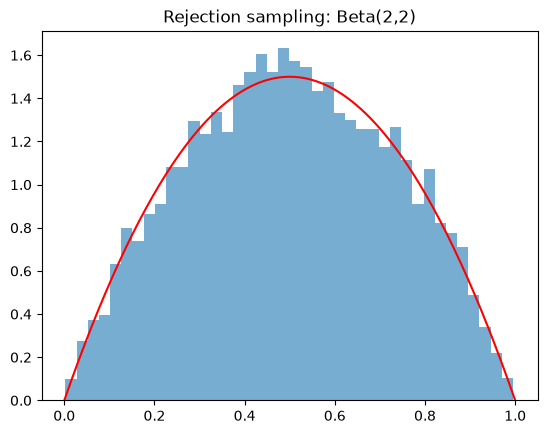

In [12]:
def rejection_beta22(n, rng):
    samples, tries = [], 0
    while len(samples) < n:
        x = rng.uniform()
        u = rng.uniform()
        tries += 1
        if u <= 4 * x * (1 - x):            # f(x) / (M g(x))
            samples.append(x)
    return np.array(samples), n / tries

rng = np.random.default_rng(SEED)
beta_s, acc_rate = rejection_beta22(10_000, rng)
print(f"Acceptance rate = {acc_rate:.3f}  (theory 0.667)")
print(f"Mean = {beta_s.mean():.4f} (theory 0.5),  Var = {beta_s.var(ddof=1):.4f} (theory {1/20:.4f})")
print("KS test vs Beta(2,2):", stats.kstest(beta_s, "beta", args=(2, 2)))

xs = np.linspace(0, 1, 200)
plt.hist(beta_s, bins=40, density=True, alpha=.6); plt.plot(xs, stats.beta.pdf(xs, 2, 2), "r")
plt.title("Rejection sampling: Beta(2,2)"); plt.show()

## Q4. The four main steps of a (bootstrap) particle filter
A particle filter approximates the filtering distribution $p(x_t\mid y_{1:t})$ of a state-space model with $N$ weighted particles $\{x_t^{(i)},w_t^{(i)}\}$.

1. **Initialise:** draw $x_0^{(i)}\sim p(x_0)$, set weights $w_0^{(i)}=1/N$.
2. **Predict (propagate):** move each particle through the transition model, $x_t^{(i)}\sim p(x_t\mid x_{t-1}^{(i)})$.
3. **Update (weight):** when observation $y_t$ arrives, reweight by the likelihood, $w_t^{(i)}\propto w_{t-1}^{(i)}\,p(y_t\mid x_t^{(i)})$, then normalise so $\sum_i w_t^{(i)}=1$.
4. **Resample:** draw $N$ particles with replacement in proportion to the weights (and reset weights to $1/N$) to avoid weight degeneracy; often done only when the effective sample size $1/\sum w_i^2$ falls below a threshold.

The state estimate is then $\hat x_t=\sum_i w_t^{(i)}x_t^{(i)}$. Small demonstration on a random-walk-plus-noise model:

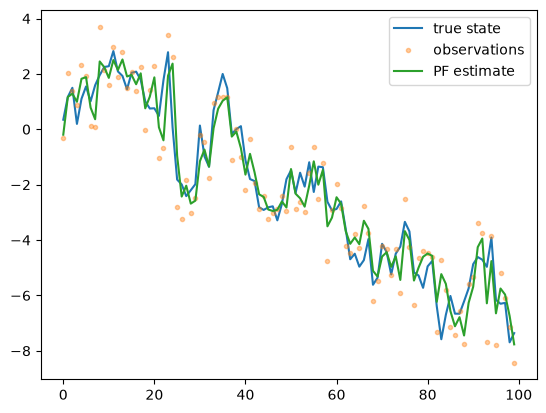

RMSE PF = 0.724   RMSE raw obs = 0.995


In [13]:
def bootstrap_particle_filter(y, N=1000, sig_x=1.0, sig_y=1.0, rng=None):
    rng = rng or np.random.default_rng(SEED)
    particles = rng.normal(0, 1, N)                           # 1. initialise
    est = []
    for yt in y:
        particles = particles + rng.normal(0, sig_x, N)       # 2. predict
        w = stats.norm.pdf(yt, loc=particles, scale=sig_y)    # 3. update weights
        w /= w.sum()
        est.append(np.sum(w * particles))
        particles = rng.choice(particles, size=N, p=w)        # 4. resample
    return np.array(est)

rng = np.random.default_rng(1)
T = 100
x_true = np.cumsum(rng.normal(0, 1, T))
y_obs_pf = x_true + rng.normal(0, 1, T)
x_hat = bootstrap_particle_filter(y_obs_pf, rng=rng)

plt.plot(x_true, label="true state"); plt.plot(y_obs_pf, ".", alpha=.4, label="observations")
plt.plot(x_hat, label="PF estimate"); plt.legend(); plt.show()
print(f"RMSE PF = {np.sqrt(np.mean((x_hat-x_true)**2)):.3f}   RMSE raw obs = {np.sqrt(np.mean((y_obs_pf-x_true)**2)):.3f}")

## Q5. What does a non-uniform SBC rank histogram indicate?
**Simulation-based calibration (SBC):** repeatedly (1) draw $\theta^*$ from the prior, (2) simulate data $y$ from $p(y\mid\theta^*)$, (3) run the inference algorithm to get posterior draws, (4) record the rank of $\theta^*$ among those draws. If the model, the sampler and the code are all correct, the ranks are **uniformly distributed**.

A non-uniform histogram signals a problem with the inference (a bug, a mis-specified model that does not match the simulator, or a sampler that is not converging/mixing). The shape is diagnostic:

* **U-shaped** (mass at both ends): posterior too narrow/**overconfident**, the true value often falls outside the posterior bulk.
* **Inverted-U / hump** (mass in the middle): posterior too wide / **underdispersed rank** (overly diffuse).
* **Skewed to the left or right** (ranks piled at one end): **biased** posterior, systematically over- or under-estimating the parameter.
* **Spikes at the edges or irregular spikes**: often autocorrelated MCMC draws (ESS too low) or a coding error. Thinning the draws can help.

---
# Lab 4: Testing, estimators, packaging
## Q1. Median function with tests for a known result and empty input
In a package these would be in `src/mypkg/stats.py` and `tests/test_stats.py` and run with `pytest`. Here they are written pytest-style and also run inline.

In [14]:
def median(values):
    """Return the median of a non-empty sequence of numbers.

    Raises
    ------
    ValueError
        If `values` is empty.
    """
    xs = sorted(values)
    n = len(xs)
    if n == 0:
        raise ValueError("median() of empty input is undefined")
    mid = n // 2
    return xs[mid] if n % 2 == 1 else (xs[mid - 1] + xs[mid]) / 2


# ---- tests (pytest style) ----
def test_median_known_odd():
    assert median([3, 1, 2]) == 2

def test_median_known_even():
    assert median([3, 4, 5, 7, 8, 9]) == 6.0     # (5+7)/2

def test_median_empty_raises():
    try:
        median([])
    except ValueError:
        pass
    else:
        raise AssertionError("expected ValueError for empty input")
    # with pytest:  with pytest.raises(ValueError): median([])

for t in (test_median_known_odd, test_median_known_even, test_median_empty_raises):
    t(); print("PASS", t.__name__)

PASS test_median_known_odd
PASS test_median_known_even
PASS test_median_empty_raises


## Q2. Tests that a probability estimate lies in [0, 1]
Estimator: posterior-mean probability with a Beta(α, β) prior, $\hat p=(k+\alpha)/(n+\alpha+\beta)$. The tests cover edge cases (k = 0, k = n) and many random inputs (a property-style test).

In [15]:
def estimate_probability(successes, trials, alpha=1.0, beta=1.0):
    if trials < 0 or successes < 0 or successes > trials:
        raise ValueError("need 0 <= successes <= trials")
    return (successes + alpha) / (trials + alpha + beta)

def test_probability_in_unit_interval_edges():
    for k, n in [(0, 0), (0, 10), (10, 10), (5, 10)]:
        p = estimate_probability(k, n)
        assert 0.0 <= p <= 1.0, (k, n, p)

def test_probability_in_unit_interval_random():
    rng = np.random.default_rng(0)
    for _ in range(1000):
        n = int(rng.integers(0, 500)); k = int(rng.integers(0, n + 1))
        p = estimate_probability(k, n, alpha=rng.uniform(.1, 5), beta=rng.uniform(.1, 5))
        assert 0.0 <= p <= 1.0

def test_probability_invalid_input():
    for bad in [(-1, 5), (6, 5)]:
        try: estimate_probability(*bad)
        except ValueError: continue
        raise AssertionError(f"expected ValueError for {bad}")

for t in (test_probability_in_unit_interval_edges, test_probability_in_unit_interval_random, test_probability_invalid_input):
    t(); print("PASS", t.__name__)
# Hypothesis version:  @given(st.integers(0, 1000).flatmap(lambda n: st.tuples(st.integers(0, n), st.just(n))))

PASS test_probability_in_unit_interval_edges
PASS test_probability_in_unit_interval_random
PASS test_probability_invalid_input


## Q3. Transformer that scales each column by its standard deviation
Follows the scikit-learn estimator API: `fit` learns the per-column standard deviations (stored with a trailing underscore), `transform` divides by them. Columns with zero variance are left unscaled to avoid division by zero.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StdScaler(BaseEstimator, TransformerMixin):
    """Scale each column by its standard deviation (no centering)."""

    def __init__(self, ddof=0):
        self.ddof = ddof

    def fit(self, X, y=None):
        X = check_array(X)
        self.n_features_in_ = X.shape[1]
        std = X.std(axis=0, ddof=self.ddof)
        self.scale_ = np.where(std == 0, 1.0, std)      # guard constant columns
        return self

    def transform(self, X):
        check_is_fitted(self, "scale_")
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("X has a different number of columns than during fit")
        return X / self.scale_

X = np.array([[1., 10., 5.], [2., 20., 5.], [3., 30., 5.], [4., 40., 5.]])
sc = StdScaler().fit(X)
Xt = sc.transform(X)
print("scale_      :", sc.scale_.round(4))
print("std after   :", Xt.std(axis=0).round(4), "(constant column left as is)")
print("fit_transform equal:", np.allclose(StdScaler().fit_transform(X), Xt))

# works inside a Pipeline
from sklearn.pipeline import make_pipeline
print(make_pipeline(StdScaler(), LogisticRegression()))

scale_      : [ 1.118  11.1803  1.    ]
std after   : [1. 1. 0.] (constant column left as is)
fit_transform equal: True
Pipeline(steps=[('stdscaler', StdScaler()),
                ('logisticregression', LogisticRegression())])


## Q4. A minimal `pyproject.toml` and editable installation
Project layout:
```
mypkg/
├── pyproject.toml
├── src/
│   └── mypkg/
│       ├── __init__.py
│       └── stats.py
└── tests/
    └── test_stats.py
```

`pyproject.toml`:
```toml
[build-system]
requires = ["setuptools>=68", "wheel"]
build-backend = "setuptools.build_meta"

[project]
name = "mypkg"
version = "0.1.0"
description = "Small statistics utilities for ICD 341"
requires-python = ">=3.9"
dependencies = ["numpy", "scikit-learn"]

[project.optional-dependencies]
dev = ["pytest"]

[tool.setuptools.packages.find]
where = ["src"]
```

**Editable installation** — `pip install -e .` (or `pip install -e ".[dev]"`) run from the folder containing `pyproject.toml`.

* Instead of copying the code into `site-packages`, pip installs a small link/path hook that points back to your source directory.
* `import mypkg` works from anywhere in that environment, but Python loads the files from your working copy, so **edits take effect immediately** without reinstalling (restart the kernel or use `%autoreload` in notebooks).
* Benefits: tests import the package the same way users will (no `sys.path` hacks), dependencies are installed, and development is fast. Reinstall is needed only when metadata changes (dependencies, entry points, new package structure).
* Use a virtual environment (`python -m venv .venv`) so the install stays isolated; for distribution use `python -m build`, which makes a regular (non-editable) wheel.

---
# Lab 5: Performance and scalability
## Q1. Vectorise $x^2+2x+1$ for one million values

In [17]:
x = np.random.default_rng(SEED).normal(size=1_000_000)

def poly_loop(x):
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = x[i]**2 + 2*x[i] + 1
    return out

def poly_vec(x):
    return x**2 + 2*x + 1            # whole-array operations in compiled C

t0 = time.perf_counter(); r_loop = poly_loop(x); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); r_vec  = poly_vec(x);  t_vec  = time.perf_counter() - t0

print(f"Python loop: {t_loop:.3f} s")
print(f"Vectorised : {t_vec*1000:.2f} ms   (~{t_loop/t_vec:.0f}x faster)")
print("Same result:", np.allclose(r_loop, r_vec))
print("Also (x+1)^2:", np.allclose(r_vec, (x + 1)**2))

Python loop: 1.649 s
Vectorised : 18.26 ms   (~90x faster)
Same result: True
Also (x+1)^2: True


## Q2. Numba function that sums the squares

In [18]:
try:
    from numba import njit

    @njit(cache=True)
    def sum_squares_numba(a):
        total = 0.0
        for i in range(a.shape[0]):
            total += a[i] * a[i]
        return total

    sum_squares_numba(x[:10])        # warm-up: triggers JIT compilation (see Q5)

    t0 = time.perf_counter(); s_nb = sum_squares_numba(x); t_nb = time.perf_counter() - t0
    t0 = time.perf_counter(); s_np = np.sum(x**2);          t_np = time.perf_counter() - t0
    print(f"Numba : {s_nb:.4f}  in {t_nb*1000:.2f} ms")
    print(f"NumPy : {s_np:.4f}  in {t_np*1000:.2f} ms")
    print("Match :", np.isclose(s_nb, s_np))
except ImportError:
    print("Numba not installed here (pip install numba). Pure-NumPy equivalent:", np.sum(x**2))

Numba : 999997.6153  in 2.75 ms
NumPy : 999997.6153  in 5.80 ms
Match : True


## Q3. Bootstrap a sample mean in parallel with joblib
Each worker gets an **independent random stream** via `SeedSequence.spawn`, which avoids the classic mistake of workers sharing/duplicating the same seed.

In [19]:
from joblib import Parallel, delayed

sample = np.random.default_rng(SEED).normal(loc=10, scale=3, size=5000)

def boot_chunk(data, n_boot, seed_seq):
    rng = np.random.default_rng(seed_seq)
    idx = rng.integers(0, len(data), size=(n_boot, len(data)))
    return data[idx].mean(axis=1)

n_jobs, B_total = 4, 2000
chunk = B_total // n_jobs
seeds = np.random.SeedSequence(SEED).spawn(n_jobs)

t0 = time.perf_counter()
parts = Parallel(n_jobs=n_jobs)(delayed(boot_chunk)(sample, chunk, s) for s in seeds)
t_par = time.perf_counter() - t0
boot_par = np.concatenate(parts)

t0 = time.perf_counter()
boot_ser = boot_chunk(sample, B_total, np.random.SeedSequence(SEED))
t_ser = time.perf_counter() - t0

print(f"Parallel: {t_par:.2f} s,  Serial: {t_ser:.2f} s  (parallel has start-up overhead; gains grow with heavier work)")
print(f"Sample mean = {sample.mean():.3f}")
print(f"Bootstrap SE (parallel) = {boot_par.std(ddof=1):.4f}   theory s/sqrt(n) = {sample.std(ddof=1)/np.sqrt(len(sample)):.4f}")
print("95% percentile interval:", np.percentile(boot_par, [2.5, 97.5]).round(3))

Parallel: 1.82 s,  Serial: 0.15 s  (parallel has start-up overhead; gains grow with heavier work)
Sample mean = 10.053
Bootstrap SE (parallel) = 0.0418   theory s/sqrt(n) = 0.0420
95% percentile interval: [ 9.965 10.134]


## Q4. Dask Array: mean of a large chunked array
Dask splits the array into chunks, builds a lazy task graph, and `.compute()` evaluates chunks in parallel without loading the whole array into memory at once.

In [20]:
try:
    import dask.array as da

    # 20,000 x 20,000 float64 = 3.2 GB if materialised; only ~80 MB per chunk is in memory at a time
    darr = da.random.normal(loc=5.0, scale=2.0, size=(20_000, 20_000), chunks=(2_500, 2_500))
    print(darr)                         # lazy: nothing computed yet
    mean_lazy = darr.mean()             # still lazy (task graph)
    t0 = time.perf_counter()
    result = mean_lazy.compute()        # executes chunk-wise, in parallel
    print(f"Mean = {result:.5f} (expected ~5.0), computed in {time.perf_counter()-t0:.1f} s")
except ImportError:
    print('Dask not installed here (pip install "dask[array]").')

dask.array<normal, shape=(20000, 20000), dtype=float64, chunksize=(2500, 2500), chunktype=numpy.ndarray>
Mean = 5.00009 (expected ~5.0), computed in 8.8 s


Tip: if memory/time is limited, reduce `size` (e.g. `(10_000, 10_000)`). Chunk size trades off scheduling overhead (too many tiny chunks) against memory use and parallelism (too few big chunks); chunks of about 10–100 MB are a good starting point.

## Q5. Why benchmark timing should exclude Numba's first call
Numba is a **just-in-time (JIT)** compiler. On the *first* call with a given argument type signature it must infer types and compile the function to machine code, which can take hundreds of milliseconds to seconds. Later calls reuse the cached compiled code and run at native speed.

So the first call's time = **compilation + execution**. Including it would:

* wildly overstate the cost of the function (compile time is a one-off, not proportional to data size);
* make Numba look slower than NumPy for small tasks, giving the wrong conclusion about steady-state performance.

**Good benchmarking practice:** call the function once as a warm-up (with the same dtypes), then time repeated calls (e.g. `%timeit`, or `timeit.repeat` and take the minimum/median). Report compilation time separately if it matters (e.g. for short-lived scripts), and use `cache=True` to persist compiled code between sessions. Also call `.compute()`/synchronise before stopping the timer for lazy or asynchronous libraries.

In [21]:
try:
    from numba import njit

    @njit
    def sum_sq(a):
        s = 0.0
        for v in a:
            s += v * v
        return s

    data_b = np.random.default_rng(0).normal(size=1_000_000)
    t0 = time.perf_counter(); sum_sq(data_b); first = time.perf_counter() - t0      # includes compilation
    runs = []
    for _ in range(20):
        t0 = time.perf_counter(); sum_sq(data_b); runs.append(time.perf_counter() - t0)
    print(f"First call (compile + run): {first*1000:8.1f} ms")
    print(f"Steady-state (median of 20): {np.median(runs)*1000:8.3f} ms")
except ImportError:
    print("Numba not installed here; run this cell after `pip install numba` to see the gap.")

First call (compile + run):    175.2 ms
Steady-state (median of 20):    3.267 ms


---
**End of Labs 9–13.**